In [1]:
import numpy as np

import torch
from torch import nn
from torch.nn import functional as F

import torchvision
from torchvision.datasets import MNIST

import matplotlib
from matplotlib import pyplot as plt
from IPython.display import clear_output

In [2]:
train_mnist_data = MNIST('.', train=True, transform = torchvision.transforms.ToTensor(), download=True)
test_mnist_data = MNIST('.', train=False, transform = torchvision.transforms.ToTensor(), download=True)

In [3]:
train_data_loader = torch.utils.data.DataLoader(
    train_mnist_data,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

In [4]:
test_data_loader = torch.utils.data.DataLoader(
    test_mnist_data,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

In [5]:
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

Text(0.5, 1.0, 'Image label: 8')

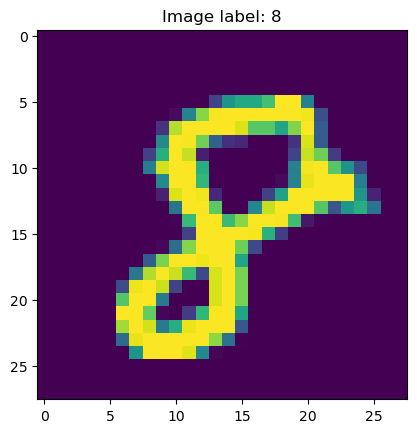

In [6]:
random_batch = next(iter(train_data_loader))
_image, _label = random_batch[0][0], random_batch[1][0]
plt.figure()
plt.imshow(_image.reshape(28,28))
plt.title(f'Image label: {_label}')

In [7]:
input_size = 784
hidden_size = 500
num_classes = 10
num_epochs = 20

In [8]:
class Net(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

In [9]:
model = Net(input_size, hidden_size, num_classes)
print(model)

Net(
  (fc1): Linear(in_features=784, out_features=500, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=500, out_features=10, bias=True)
)


In [10]:
assert model is not None, 'Please, use `model` variable to store your model'

try:
    x = random_batch[0].reshape(-1, 784)
    y = random_batch[1]

    y_predicted = model(x)
except Exception as e:
    print('Something is wrong with the model')
    raise e

assert y_predicted.shape[-1] == 10, 'Model should predict 10 logits/probas'

print('Everything seems fine!')

Everything seems fine!


In [11]:
from torch.autograd import Variable
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [12]:
for epoch in range(num_epochs):
    for i, (images, labels) in enumerate(train_data_loader):

        optimizer.zero_grad()
        outputs = model(Variable(images.view(-1,28*28)))
        loss = loss_function(outputs, Variable(labels))
        loss.backward()
        optimizer.step()

        if (i+1)%100 == 0:
            print('Epoch: [%d], Step: %d, Loss: %.4f'
                  %(epoch+1, i+1, loss.item()))
        

Epoch: [1], Step: 100, Loss: 0.2130
Epoch: [1], Step: 200, Loss: 0.1551
Epoch: [1], Step: 300, Loss: 0.2511
Epoch: [1], Step: 400, Loss: 0.3039
Epoch: [1], Step: 500, Loss: 0.2892
Epoch: [1], Step: 600, Loss: 0.0832
Epoch: [1], Step: 700, Loss: 0.4100
Epoch: [1], Step: 800, Loss: 0.2213
Epoch: [1], Step: 900, Loss: 0.0941
Epoch: [1], Step: 1000, Loss: 0.1259
Epoch: [1], Step: 1100, Loss: 0.0823
Epoch: [1], Step: 1200, Loss: 0.1444
Epoch: [1], Step: 1300, Loss: 0.0140
Epoch: [1], Step: 1400, Loss: 0.0669
Epoch: [1], Step: 1500, Loss: 0.1524
Epoch: [1], Step: 1600, Loss: 0.0607
Epoch: [1], Step: 1700, Loss: 0.0685
Epoch: [1], Step: 1800, Loss: 0.0703
Epoch: [2], Step: 100, Loss: 0.0157
Epoch: [2], Step: 200, Loss: 0.1103
Epoch: [2], Step: 300, Loss: 0.0566
Epoch: [2], Step: 400, Loss: 0.0972
Epoch: [2], Step: 500, Loss: 0.1237
Epoch: [2], Step: 600, Loss: 0.0826
Epoch: [2], Step: 700, Loss: 0.0305
Epoch: [2], Step: 800, Loss: 0.0455
Epoch: [2], Step: 900, Loss: 0.0360
Epoch: [2], Step: 1

In [13]:
predicted_labels = []
real_labels = []
model.eval()
with torch.no_grad():
    for batch in train_data_loader:
        y_predicted = model(batch[0].reshape(-1, 784))
        predicted_labels.append(y_predicted.argmax(dim=1))
        real_labels.append(batch[1])

predicted_labels = torch.cat(predicted_labels)
real_labels = torch.cat(real_labels)
train_acc = (predicted_labels == real_labels).type(torch.FloatTensor).mean()

In [14]:
print(f'Neural network accuracy on train set: {train_acc:3.5}')

Neural network accuracy on train set: 0.99828


In [15]:
predicted_labels = []
real_labels = []
model.eval()
with torch.no_grad():
    for batch in test_data_loader:
        y_predicted = model(batch[0].reshape(-1, 784))
        predicted_labels.append(y_predicted.argmax(dim=1))
        real_labels.append(batch[1])

predicted_labels = torch.cat(predicted_labels)
real_labels = torch.cat(real_labels)
test_acc = (predicted_labels == real_labels).type(torch.FloatTensor).mean()

In [16]:
print(f'Neural network accuracy on test set: {test_acc:3.5}')

Neural network accuracy on test set: 0.9809


In [17]:
assert test_acc >= 0.92, 'Test accuracy is below 0.92 threshold'
assert train_acc >= 0.91, 'Train accuracy is below 0.91 while test accuracy is fine. We recommend to check your model and data flow'

In [18]:
import os
import json
assert os.path.exists('hw_mnist_data_dict.npy'), 'Please, download `hw_mnist_data_dict.npy` and place it in the working directory'

def get_predictions(model, eval_data, step=10):
    
    predicted_labels = []
    model.eval()
    with torch.no_grad():
        for idx in range(0, len(eval_data), step):
            y_predicted = model(eval_data[idx:idx+step].reshape(-1, 784))
            predicted_labels.append(y_predicted.argmax(dim=1))
    
    predicted_labels = torch.cat(predicted_labels).numpy()
    predicted_labels = ','.join([str(x) for x in list(predicted_labels)])
    return predicted_labels

loaded_data_dict = np.load('hw_mnist_data_dict.npy', allow_pickle=True)

submission_dict = {
    'train': get_predictions(model, torch.FloatTensor(loaded_data_dict.item()['train'])),
    'test': get_predictions(model, torch.FloatTensor(loaded_data_dict.item()['test']))
}

with open('submission_dict_mnist.json', 'w') as iofile:
    json.dump(submission_dict, iofile)
print('File saved to `submission_dict_mnist.json`')

File saved to `submission_dict_mnist.json`
